# Stacking and differential light curve of UCAC4 505-089157
Occultation of UCAC4 505-089157 (Gaia DR3 4504025039616552576, G = 14.65) by (754) Malabar, 2024-07-15, about 22:22 UT, LFOA 1.5 m with PICO.

Input: the corrected frames from `data reduction.ipynb` in `20240715_reduced/`. All helper functions are in `photometry.py`. All times are UT from the `MJD-OBS` header keyword, which has a resolution of 1 s.

In [1]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from astropy.table import Table
from astropy.time import Time
from photutils.aperture import CircularAperture

from photometry import (GAIN, list_sequences, read_frames, frame_times, file_offset, frame_shifts, measure_fwhm, centroid,
                        aperture_photometry, flux_error, stack_frames, solve_field, source_mask, background_surface)

warnings.filterwarnings('ignore', message='.*NaNs or infs.*')
warnings.filterwarnings('ignore', message='Mean of empty slice')

TARGET_ID = 4504025039616552576
APERTURE = 30          # px, contains the star and the asteroid while they are blended
MIN_SNR = 20           # wanted signal to noise ratio of the target per light curve point
EVENT_DURATION = 7.0   # s, the 8 published chords last 5.9 to 7.5 s
PRE_BLEND_END = 22.20  # UT hours; before this the asteroid is far from the target
DEFOCUSED = ['201358', '201938']  # focus was still being adjusted, the stars do not fit in the aperture
EVENT_CUBES = ['221526', '222213', '222434']
SHORT_SINGLES = ['204029', '204233', '204426', '205325']

BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.7, 'axes.axisbelow': True})

output_dir = '20240715_reduced/stacked'
os.makedirs(output_dir, exist_ok=True)

sequences = list_sequences()
for s in sequences:
    print(f"{s['name']}  {s['n_frames']:3d} frames  t_exp = {s['exptime']:6.3f} s  cycle = {s['cycle_time']:7.3f} s")


def to_datetime(mjd):
    return Time(mjd, format='mjd').to_datetime()


def ut_hours(mjd):
    return (np.asarray(mjd) - 60506) * 24

201358    1 frames  t_exp = 30.000 s  cycle =  30.010 s
201938    1 frames  t_exp = 30.000 s  cycle =  30.010 s
202451    1 frames  t_exp = 30.000 s  cycle =  30.010 s
202833    1 frames  t_exp = 30.000 s  cycle =  30.010 s
203217    1 frames  t_exp = 30.000 s  cycle =  30.010 s
203532    1 frames  t_exp = 30.000 s  cycle =  30.010 s
204029    1 frames  t_exp =  0.100 s  cycle =  30.010 s
204233    1 frames  t_exp =  0.500 s  cycle =  30.010 s
204426    1 frames  t_exp =  0.300 s  cycle =  30.010 s
205325    1 frames  t_exp =  0.400 s  cycle =  30.010 s
205830   10 frames  t_exp =  0.300 s  cycle =  30.010 s
210956   10 frames  t_exp =  0.300 s  cycle =  30.010 s
211959   10 frames  t_exp =  0.300 s  cycle =   1.010 s
214211   10 frames  t_exp =  0.300 s  cycle =   3.333 s
220025   10 frames  t_exp =  0.500 s  cycle =   1.010 s
220333   10 frames  t_exp =  0.400 s  cycle =   1.010 s
220826   10 frames  t_exp =  0.300 s  cycle =   1.010 s
221526  100 frames  t_exp =  0.300 s  cycle =   

## Target and comparison stars
The WCS in the headers is about 2 arcmin off, and the 30 s frames have no WCS at all, so the sharpest 30 s frame (`203532`) is solved against Gaia DR3 and used as the reference image. `gaia_field.csv` is the Gaia query of this field, saved so that the notebook works offline.

In [2]:
reference_sequence = next(s for s in sequences if s['name'] == '203532')
reference = read_frames(reference_sequence)[0]

catalog = Table.read('gaia_field.csv', format='ascii.csv')
catalog = catalog[catalog['phot_g_mean_mag'] < 19.5]
wcs_header = fits.getheader('20240715/20240715T222434.0.pico.object.fits')
star_x, star_y, rms, n_matched = solve_field(reference, catalog, wcs_header)
print(f"Plate solution: {n_matched} stars matched, rms {rms:.1f} px")

target_index = int(np.where(catalog['source_id'] == TARGET_ID)[0][0])
target_position = np.array(centroid(reference, star_x[target_index], star_y[target_index]))
print(f"Target at ({target_position[0]:.1f}, {target_position[1]:.1f}), "
      f"{np.hypot(*(target_position - [star_x[target_index], star_y[target_index]])):.1f} px from the catalog position")

# Comparison stars: bright, away from the vignetted edge, no comparably bright neighbour
gmag = np.array(catalog['phot_g_mean_mag'])
candidates = np.where((gmag < 15.3) & (np.hypot(star_x - 1024, star_y - 1024) < 880))[0]
isolated = [not np.any((np.hypot(star_x - star_x[i], star_y - star_y[i]) > 0)
                       & (np.hypot(star_x - star_x[i], star_y - star_y[i]) < 45) & (gmag < gmag[i] + 2.5))
            for i in candidates]
candidates = candidates[np.array(isolated)]
candidates = candidates[candidates != target_index]
comparison_index = candidates[np.argsort(gmag[candidates])][:5]
comparison_positions = np.array([centroid(reference, star_x[i], star_y[i]) for i in comparison_index])

for i, (x, y) in zip(comparison_index, comparison_positions):
    print(f"Comparison star Gaia {catalog['source_id'][i]}  G = {gmag[i]:.2f}  at ({x:.1f}, {y:.1f})")

Plate solution: 59 stars matched, rms 2.5 px
Target at (1255.8, 1055.7), 3.7 px from the catalog position
Comparison star Gaia 4504031013889014400  G = 12.65  at (650.9, 1557.3)
Comparison star Gaia 4504030708973367552  G = 13.48  at (615.7, 984.7)
Comparison star Gaia 4504024799098355584  G = 14.19  at (1294.9, 397.8)
Comparison star Gaia 4504030708973353088  G = 14.21  at (299.9, 802.4)
Comparison star Gaia 4504025005256815360  G = 14.29  at (1664.0, 933.6)


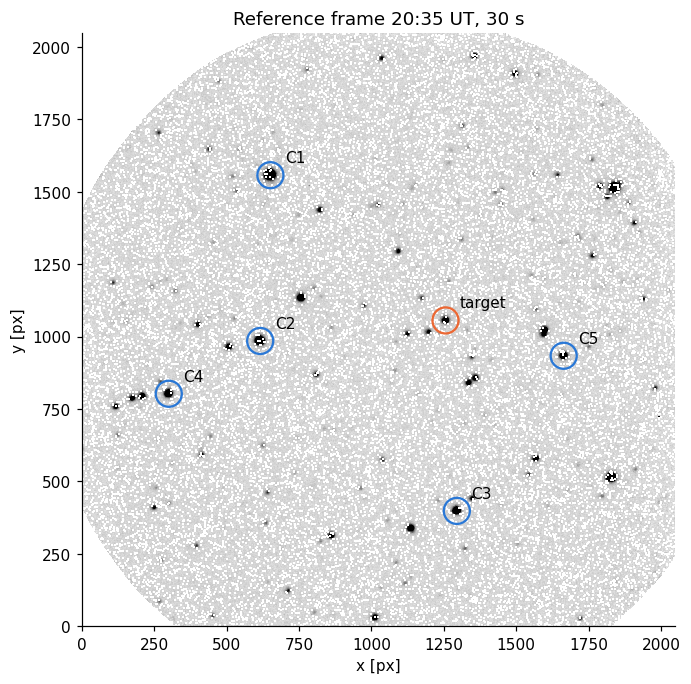

In [3]:
fig, ax = plt.subplots(figsize=(7, 7))
vmin, vmax = np.nanpercentile(reference, [5, 99.7])
ax.imshow(reference, origin='lower', cmap='gray_r', vmin=vmin, vmax=vmax)
ax.grid(False)
ax.add_patch(plt.Circle(target_position, 45, fill=False, color=ORANGE, lw=1.5))
ax.annotate('target', target_position + [50, 45], color='black')
for n, position in enumerate(comparison_positions):
    ax.add_patch(plt.Circle(position, 45, fill=False, color=BLUE, lw=1.5))
    ax.annotate(f'C{n + 1}', position + [50, 45], color='black')
ax.set_xlabel('x [px]')
ax.set_ylabel('y [px]')
ax.set_title('Reference frame 20:35 UT, 30 s')
plt.show()

## Alignment
The telescope drifts by tens of pixels between sequences and by 2-5 px (rms) inside a cube. Every frame is measured against the reference image with the centroids of the comparison stars.

In [4]:
positions = np.vstack([target_position, comparison_positions])
shifts = {}
fwhm = {}

for s in sequences:
    frames = read_frames(s)
    mean_image = np.nanmean(frames, axis=0)
    offset = file_offset(mean_image, reference)
    shifts[s['name']] = frame_shifts(frames, comparison_positions, offset)
    fwhm[s['name']] = measure_fwhm(mean_image, comparison_positions + np.array(offset))
    print(f"{s['name']}: FWHM {fwhm[s['name']]:5.1f} px, drift rms {shifts[s['name']].std(axis=0).round(1)} px")

201358: FWHM  26.8 px, drift rms [0. 0.] px


201938: FWHM  15.7 px, drift rms [0. 0.] px


202451: FWHM  12.4 px, drift rms [0. 0.] px


202833: FWHM  10.2 px, drift rms [0. 0.] px


203217: FWHM  10.6 px, drift rms [0. 0.] px


203532: FWHM  10.9 px, drift rms [0. 0.] px


... (10 outputs left out)

220826: FWHM  10.7 px, drift rms [1.9 1.7] px


221526: FWHM  11.5 px, drift rms [5.  2.3] px


222213: FWHM  11.1 px, drift rms [3.5 2. ] px


222434: FWHM  10.6 px, drift rms [2.3 1.7] px


## The asteroid track
Malabar is visible in almost every sequence. Its centroid gives three things:
1. The time of the conjunction with the star, independent of the prediction.
2. A check of the cycle times, since the `KCT` header keyword looks odd for some cubes (30 s for frames of 0.3 s).
3. The contamination of the target aperture, which starts long before the occultation.

Rate at the end: (4.63, -0.72) px/min = 0.492 arcsec/min, scatter (0.54, 0.46) px


Conjunction from the free track: 22:22:29 UT +/- 4 s, closest approach 0.06 px +/- 0.46 px
Conjunction from the blended photocentre: 22:22:32 UT +/- 4 s

Cycle time check (frames at both ends of a cube):
  205830: asteroid moved  13.7 px, gives  35.0 s per frame; KCT = 30.01 s
  210956: asteroid moved  11.4 px, gives  29.2 s per frame; KCT = 30.01 s
  221526: asteroid moved   7.6 px, gives   1.1 s per frame; KCT = 1.01 s
  222213: asteroid moved   4.9 px, gives   0.7 s per frame; KCT = 1.01 s
  222434: asteroid moved   7.7 px, gives   1.1 s per frame; KCT = 1.01 s


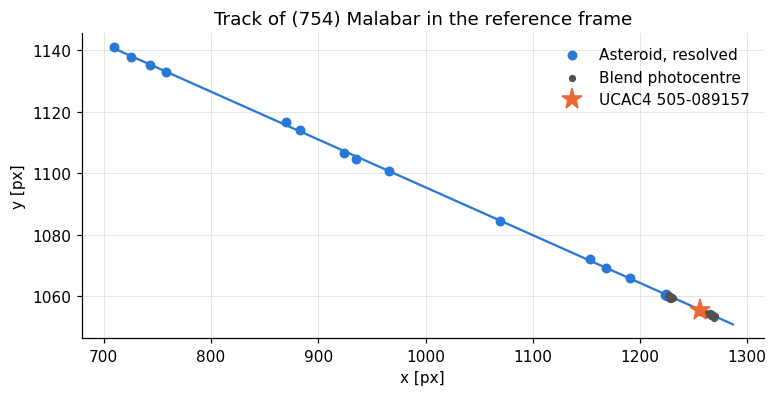

In [5]:
def asteroid_groups(s):
    n = s['n_frames']
    if n == 100:
        return [np.arange(i, i + 10) for i in range(0, 100, 10)]
    if n == 10 and s['cycle_time'] > 20:
        return [np.arange(0, 5), np.arange(5, 10)]
    return [np.arange(n)]


rate_guess = np.array([4.67, -0.73])  # px/min, from the positions of the asteroid at 20:35 and 22:16
position_guess = np.array([757.7, 1133.1])
time_guess = 60506 + 20.5964 / 24

track = []
for s in sequences:
    if s['name'] in DEFOCUSED or s['name'] in SHORT_SINGLES:
        continue
    frames = read_frames(s)
    times = frame_times(s)
    for group in asteroid_groups(s):
        image = stack_frames(frames[group], shifts[s['name']][group])
        mjd = times[group].mean()
        guess = position_guess + rate_guess * (mjd - time_guess) * 1440
        x, y = centroid(image, *guess, half_box=25, smooth=3)
        x, y = centroid(image, x, y, half_box=16, smooth=2)
        track.append((s['name'], mjd, x, y))

track = Table(rows=track, names=['seq', 'mjd', 'x', 'y'])
minutes = (track['mjd'] - time_guess) * 1440
separation = np.hypot(track['x'] - target_position[0], track['y'] - target_position[1])
free = (separation > 30) & (ut_hours(track['mjd']) < 22.32)

# Quadratic fit in time to the positions where the asteroid is resolved from the star
fit_x = np.polyfit(minutes[free], track['x'][free], 2)
fit_y = np.polyfit(minutes[free], track['y'][free], 2)
scatter_x = np.std(track['x'][free] - np.polyval(fit_x, minutes[free]))
scatter_y = np.std(track['y'][free] - np.polyval(fit_y, minutes[free]))
rate = (np.polyval(np.polyder(fit_x), minutes[free][-1]), np.polyval(np.polyder(fit_y), minutes[free][-1]))
print(f"Rate at the end: ({rate[0]:.2f}, {rate[1]:.2f}) px/min = {np.hypot(*rate) * 0.105:.3f} arcsec/min, scatter ({scatter_x:.2f}, {scatter_y:.2f}) px")


def track_position(mjd):
    t = (np.asarray(mjd) - time_guess) * 1440
    return np.polyval(fit_x, t), np.polyval(fit_y, t)


# Conjunction time with a bootstrap over the track points
def conjunction(index):
    fx = np.polyfit(minutes[index], track['x'][index], 2)
    fy = np.polyfit(minutes[index], track['y'][index], 2)
    t = np.linspace(minutes.max() - 25, minutes.max() + 5, 3001)
    d2 = (np.polyval(fx, t) - target_position[0]) ** 2 + (np.polyval(fy, t) - target_position[1]) ** 2
    return t[d2.argmin()], np.sqrt(d2.min())


rng = np.random.default_rng(1)
free_index = np.where(free)[0]
boot = np.array([conjunction(rng.choice(free_index, len(free_index))) for _ in range(500)])
t_conjunction = conjunction(free_index)
mjd_conjunction = time_guess + t_conjunction[0] / 1440
sigma_conjunction = boot[:, 0].std() * 60
print(f"Conjunction from the free track: {to_datetime(mjd_conjunction).strftime('%H:%M:%S')} UT +/- {sigma_conjunction:.0f} s, "
      f"closest approach {t_conjunction[1]:.2f} px +/- {boot[:, 1].std():.2f} px")

# Second estimate: the photocentre of the blend also crosses the star position at the conjunction
blended = np.isin(track['seq'], ['222213', '222434'])
t_mean = minutes[blended].mean()
fit_blend, cov_blend = np.polyfit(minutes[blended] - t_mean, track['x'][blended] - target_position[0], 1, cov=True)
t_blend = t_mean - fit_blend[1] / fit_blend[0]
sigma_blend = 60 * np.hypot(np.sqrt(cov_blend[1, 1]) / fit_blend[0], fit_blend[1] * np.sqrt(cov_blend[0, 0]) / fit_blend[0] ** 2)
mjd_blend = time_guess + t_blend / 1440
print(f"Conjunction from the blended photocentre: {to_datetime(mjd_blend).strftime('%H:%M:%S')} UT +/- {sigma_blend:.0f} s")

# Check of the cycle times: motion of the asteroid per frame inside a sequence, against the track
print("\nCycle time check (frames at both ends of a cube):")
for s in sequences:
    t = track[track['seq'] == s['name']]
    if len(t) < 2 or s['n_frames'] < 10:
        continue
    moved = np.hypot(t['x'][-1] - t['x'][0], t['y'][-1] - t['y'][0])
    frames_apart = (t['mjd'][-1] - t['mjd'][0]) * 86400 / s['cycle_time']
    seconds = moved / np.hypot(*rate) * 60
    print(f"  {s['name']}: asteroid moved {moved:5.1f} px, gives {seconds / frames_apart:5.1f} s per frame; KCT = {s['cycle_time']:.2f} s")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(track['x'][free], track['y'][free], s=30, color=BLUE, label='Asteroid, resolved', zorder=3)
ax.scatter(track['x'][~free], track['y'][~free], s=14, color=GREY, label='Blend photocentre', zorder=3)
curve = np.linspace(minutes.min(), minutes.max() + 3, 200)
ax.plot(np.polyval(fit_x, curve), np.polyval(fit_y, curve), color=BLUE, lw=1.5)
ax.plot(*target_position, '*', color=ORANGE, ms=14, label='UCAC4 505-089157', zorder=4)
ax.set_xlabel('x [px]')
ax.set_ylabel('y [px]')
ax.set_title('Track of (754) Malabar in the reference frame')
ax.legend(frameon=False)
plt.show()

## Background
In the 0.3 s frames the sky is below 1 ADU per pixel, and a residual pattern of about 0.4 ADU stays fixed on the detector. Over the 2800 pixels of the aperture, 0.1 ADU is 280 ADU, a quarter of the star's flux in one frame, so a sky annulus is not good enough here: it made the star look 0.2 mag too faint.

The short exposures therefore share one smooth pattern, built in detector coordinates from all their frames with every star and the asteroid masked, plus a very smooth surface per sequence for the sky level and gradient. The 30 s frames, where this does not matter, get their own surface. Blank-sky apertures in each stack then measure what really remains: this replaces the read noise and sky terms of the error, so the error bars include the residual pattern.

In [6]:
mask_radius = np.where(gmag < 13.5, 70, np.where(gmag < 15.5, 45, np.where(gmag < 17.5, 30, 20)))


def sequence_mask(s, mean_image):
    frame_shift = shifts[s['name']]
    mean_shift = frame_shift.mean(axis=0)
    sources = list(zip(star_x + mean_shift[0], star_y + mean_shift[1]))
    radii = list(mask_radius)
    tx, ty = track_position(frame_times(s))
    sources += list(zip(tx + frame_shift[:, 0], ty + frame_shift[:, 1]))
    radii += [35] * s['n_frames']
    return source_mask(mean_image.shape, sources, radii)


total = None
for s in sequences:
    if s['exptime'] > 1:
        continue
    frames = read_frames(s)
    mean_image = np.nanmean(frames, axis=0)
    good = np.isfinite(mean_image) & ~sequence_mask(s, mean_image)
    if total is None:
        total, weight = np.zeros_like(mean_image), np.zeros_like(mean_image)
    total[good] += mean_image[good] * s['n_frames']
    weight[good] += s['n_frames']

pattern = background_surface(np.where(weight > 0, total / np.where(weight > 0, weight, 1), np.nan), np.zeros_like(weight, dtype=bool))
sky_surface = {}
sky_level = {}
for s in sequences:
    frames = read_frames(s)
    mean_image = np.nanmean(frames, axis=0)
    mask = sequence_mask(s, mean_image)
    if s['exptime'] > 1:
        sky_surface[s['name']] = background_surface(mean_image, mask)
        sky_level[s['name']] = float(np.nanmedian(sky_surface[s['name']]))
    else:
        # What is left per sequence (sky level and gradient) is very smooth. Clipped, because a median is biased on integer data
        residual = mean_image - pattern
        level, _, spread = sigma_clipped_stats(residual[~mask], sigma=4, maxiters=3)
        sky_surface[s['name']] = pattern + background_surface(residual, mask | (np.abs(residual - level) > 4 * spread), sigma=100)
        sky_level[s['name']] = float(np.nanmedian(mean_image[~mask]))
    print(f"{s['name']}: sky {sky_level[s['name']]:6.2f} ADU per pixel and frame")


def read_corrected(s):
    return read_frames(s) - sky_surface[s['name']]


# Blank-sky apertures, in the coordinates of the reference image
occupied = source_mask(reference.shape, list(zip(star_x, star_y)), mask_radius + APERTURE)
track_mjd = np.linspace(frame_times(sequences[0])[0], frame_times(sequences[-1])[-1], 300)
occupied |= source_mask(reference.shape, list(zip(*track_position(track_mjd))), [80] * len(track_mjd))
yy, xx = np.indices(reference.shape)
free_x, free_y = xx[(np.hypot(xx - 1024, yy - 1024) < 780) & ~occupied], yy[(np.hypot(xx - 1024, yy - 1024) < 780) & ~occupied]
rng = np.random.default_rng(2)
pick = rng.choice(len(free_x), 40, replace=False)
blank_positions = np.c_[free_x[pick], free_y[pick]].astype(float)
del xx, yy


def blank_scatter(image):
    """Mean and scatter of the flux in the blank apertures of an image."""
    values = np.array([aperture_photometry(image, x, y, APERTURE)[0] for x, y in blank_positions])
    return np.nanmean(values), np.nanstd(values)

201358: sky  97.91 ADU per pixel and frame


201938: sky  70.06 ADU per pixel and frame


202451: sky  54.97 ADU per pixel and frame


202833: sky  48.54 ADU per pixel and frame


203217: sky  43.52 ADU per pixel and frame


203532: sky  40.53 ADU per pixel and frame


... (10 outputs left out)

220826: sky   1.01 ADU per pixel and frame


221526: sky   1.15 ADU per pixel and frame


222213: sky   1.14 ADU per pixel and frame


222434: sky   1.14 ADU per pixel and frame


## Photometry of every single frame
The target aperture is placed at the known position of the star, shifted with the frame, and is never recentred on the target. This keeps it from following the asteroid.

In [7]:
frame_table = {key: [] for key in ['seq', 'frame', 'mjd', 'flux']}

for s in sequences:
    frames = read_corrected(s)
    for i, (frame, mjd, shift) in enumerate(zip(frames, frame_times(s), shifts[s['name']])):
        results = [aperture_photometry(frame, x + shift[0], y + shift[1], APERTURE)[0] for x, y in positions]
        frame_table['seq'].append(s['name'])
        frame_table['frame'].append(i)
        frame_table['mjd'].append(mjd)
        frame_table['flux'].append(results)

frame_table = {key: np.array(value) for key, value in frame_table.items()}


def per_frame_ratio(name):
    """Target flux / sum of the comparison stars for all frames of a sequence."""
    m = frame_table['seq'] == name
    return frame_table['flux'][m, 0] / frame_table['flux'][m, 1:].sum(axis=1)

## How many frames to add up?
The target is faint and read-noise limited in 0.3 s (a star spread over about 2800 aperture pixels, 3.15 ADU read noise per pixel), so the SNR grows as $\sqrt{N}$.

Two things limit $N$:
- The occultation lasts about 7 s at a cycle of 1.01 s. To resolve it, a bin must be at most half of that.
- Before and after the event, nothing changes quickly, so all frames of a short sequence can be added.

The table compares the predicted SNR with the measured scatter of target/comparison in the plateau cube.

  N  t_bin[s]  SNR blend predicted  measured  SNR star alone predicted
  1      1.0                 14.3      10.6                       5.0
  2      2.0                 20.3      14.8                       7.1
  3      3.0                 24.8      18.0                       8.7
  4      4.0                 28.6      18.6                      10.1
  5      5.0                 32.0      28.0                      11.3
  7      7.1                 37.9      43.6                      13.3
 10     10.1                 45.3      41.5                      15.9
 20     20.2                 64.1     136.0                      22.5
 33     33.3                 82.3       nan                      29.0
 50     50.5                101.3       nan                      35.7
100    101.0                143.2       nan                      50.4

Measured SNR per frame in the event cube: 10.6. SNR >= 20 needs N = 4; resolving the event allows N <= 3
Chosen: N = 3, bin = 3.0 s, expected SNR 18.4
Star al

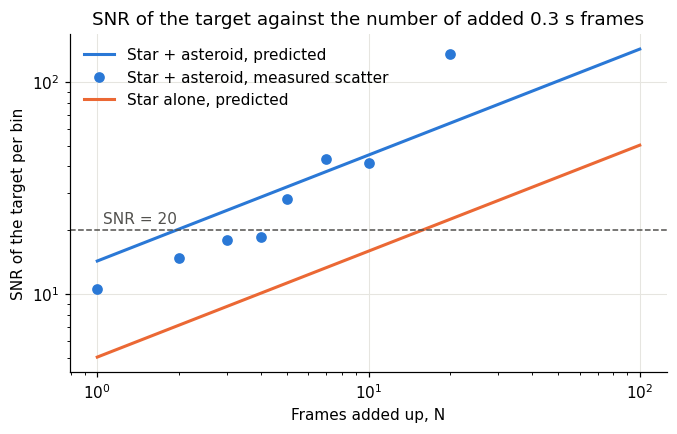

In [8]:
name = '222213'
plateau = next(s for s in sequences if s['name'] == name)
m = frame_table['seq'] == name
flux_1 = np.median(frame_table['flux'][m, 0])
ratio = frame_table['flux'][m, 0] / frame_table['flux'][m, 1:].sum(axis=1)
ratio = ratio / np.median(ratio)
sky_1 = sky_level[name]


def snr_prediction(flux, sky, N):
    return N * flux / flux_error(N * flux, N * sky, APERTURE, 1e6, N)


Ns = np.array([1, 2, 3, 4, 5, 7, 10, 20, 33, 50, 100])
predicted = np.array([snr_prediction(flux_1, sky_1, N) for N in Ns])
measured = []
for N in Ns:
    binned = ratio[:len(ratio) // N * N].reshape(-1, N).mean(axis=1)
    measured.append(1 / np.std(binned) if len(binned) >= 5 else np.nan)
measured = np.array(measured)

# Star alone, before the asteroid arrives
alone = ['211959', '214211', '220826']
m_alone = np.isin(frame_table['seq'], alone)
flux_alone = np.median(frame_table['flux'][m_alone, 0])
predicted_alone = np.array([snr_prediction(flux_alone, sky_level['220826'], N) for N in Ns])

print('  N  t_bin[s]  SNR blend predicted  measured  SNR star alone predicted')
for row in zip(Ns, Ns * plateau['cycle_time'], predicted, measured, predicted_alone):
    print(f"{row[0]:3d}  {row[1]:7.1f}  {row[2]:19.1f}  {row[3]:8.1f}  {row[4]:24.1f}")

snr_frame = 1 / np.std(ratio)
N_required = int(np.ceil((MIN_SNR / snr_frame) ** 2))
N_limit = int(EVENT_DURATION / 2 / plateau['cycle_time'])
N_EVENT = min(N_required, N_limit)
print(f"\nMeasured SNR per frame in the event cube: {snr_frame:.1f}. SNR >= {MIN_SNR} needs N = {N_required}; resolving the event allows N <= {N_limit}")
print(f"Chosen: N = {N_EVENT}, bin = {N_EVENT * plateau['cycle_time']:.1f} s, expected SNR {snr_frame * np.sqrt(N_EVENT):.1f}")
print(f"Star alone: SNR >= {MIN_SNR} needs N = {(MIN_SNR / predicted_alone[0]) ** 2:.0f} frames of 0.3 s")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(Ns, predicted, color=BLUE, lw=2, label='Star + asteroid, predicted')
ax.loglog(Ns, measured, 'o', color=BLUE, ms=6, label='Star + asteroid, measured scatter')
ax.loglog(Ns, predicted_alone, color=ORANGE, lw=2, label='Star alone, predicted')
ax.axhline(MIN_SNR, color=GREY, lw=1, ls='--')
ax.annotate(f'SNR = {MIN_SNR}', (1.05, MIN_SNR * 1.08), color=GREY)
ax.set_xlabel('Frames added up, N')
ax.set_ylabel('SNR of the target per bin')
ax.set_title('SNR of the target against the number of added 0.3 s frames')
ax.legend(frameon=False)
plt.show()

## Stacking
Stacks written to `20240715_reduced/stacked/`, always the sum of the aligned frames:
- **Event cubes** (100 frames): bins of `N_EVENT` frames for the light curve, plus the sum of the whole cube.
- **10-frame cubes**: sum of all frames. The star-alone SNR needed more than these 10 frames can give in the 0.3 s cubes, but the asteroid is far away and nothing is lost.
- **Single short frames 20:40-20:53**: added into one image.
- **30 s frames**: taken as they are, after dropping the two defocused ones.
- **Deep image**: all 300 frames of the event cubes, to check the depth.

In [9]:
stack_list = []   # one entry per light curve point
whole_cubes = {}


def make_stack(frames, frame_shift, s, index):
    image = stack_frames(frames, frame_shift)
    times = frame_times(s)[index]
    return image, float(times.mean())


def add_point(image, mjd, name, n_frames, exptime, kind):
    flux = [aperture_photometry(image, x, y, APERTURE)[0] for x, y in positions]
    blank_mean, blank_std = blank_scatter(image)
    stack_list.append({'seq': name, 'n_frames': n_frames, 'exptime': exptime, 'mjd': mjd, 'kind': kind,
                       'flux': flux, 'blank_mean': blank_mean, 'blank_std': blank_std})


def write_stack(path, image, reference_sequence_info, n_frames, exptime, mjd):
    header = fits.getheader(reference_sequence_info['file'])
    header['EXPTIME'] = (exptime, 'Total exposure time of the stack [s]')
    header['NCOMBINE'] = (n_frames, 'Number of frames added up')
    header['MJD-MID'] = (mjd, 'Mean MJD of the mid-exposures')
    header['BUNIT'] = 'adu'
    header['HISTORY'] = 'Sum of frames aligned on the reference frame 203532; header WCS is not valid'
    fits.writeto(path, image.astype(np.float32), header, overwrite=True)


deep_frames = 0
deep_image = None

for s in sequences:
    name = s['name']
    if name in DEFOCUSED or name in SHORT_SINGLES:
        continue
    frames = read_corrected(s)
    frame_shift = shifts[name]
    n = len(frames)

    if n == 1:
        add_point(frames[0], float(frame_times(s)[0]), name, 1, s['exptime'], 'single')
        continue

    index = np.arange(n)
    whole, mjd = make_stack(frames, frame_shift, s, index)
    write_stack(f"{output_dir}/{name}.stack{n:03d}.fits", whole, s, n, n * s['exptime'], mjd)

    if name in EVENT_CUBES:
        whole_cubes[name] = (whole, mjd)
        add_point(whole, mjd, name, n, n * s['exptime'], 'whole cube')
        deep_image = whole if deep_image is None else deep_image + whole
        deep_frames += n
        bins = []
        for start in range(0, n - N_EVENT + 1, N_EVENT):
            index = np.arange(start, start + N_EVENT)
            image, mjd = make_stack(frames[index], frame_shift[index], s, index)
            add_point(image, mjd, name, N_EVENT, N_EVENT * s['exptime'], 'event bin')
            bins.append(image)
        fits.writeto(f"{output_dir}/{name}.bins{N_EVENT:02d}.fits", np.array(bins, dtype=np.float32), overwrite=True)
    else:
        add_point(whole, mjd, name, n, n * s['exptime'], 'short cube')

# The single short frames, added up
singles = [s for s in sequences if s['name'] in SHORT_SINGLES]
frames = np.array([read_corrected(s)[0] for s in singles])
frame_shift = np.vstack([shifts[s['name']] for s in singles])
image = stack_frames(frames, frame_shift)
mjd = float(np.mean([frame_times(s)[0] for s in singles]))
exptime = sum(s['exptime'] for s in singles)
add_point(image, mjd, 'singles', len(singles), exptime, 'short cube')
write_stack(f"{output_dir}/singles.stack{len(singles):03d}.fits", image, singles[0], len(singles), exptime, mjd)

write_stack(f"{output_dir}/deep.stack{deep_frames:03d}.fits", deep_image, plateau, deep_frames,
            deep_frames * plateau['exptime'], np.mean([v[1] for v in whole_cubes.values()]))
print(f"{len(stack_list)} light curve points")

114 light curve points


## Depth of the deep image
Are the faint stars visible? Every Gaia star in the field is measured on the sum of the 300 frames (90 s), and the fraction detected is listed per magnitude.

 G range    stars  median SNR  detected (SNR >= 5)
  12-13         1       745.2     100 %
  13-14         1       380.5     100 %
  14-15         6       194.0     100 %
  15-16        14        73.1     100 %
  16-17        13        29.5     100 %
  17-18        40        10.0      72 %
  18-19        99         5.6      53 %
  19-20        59         2.4      29 %


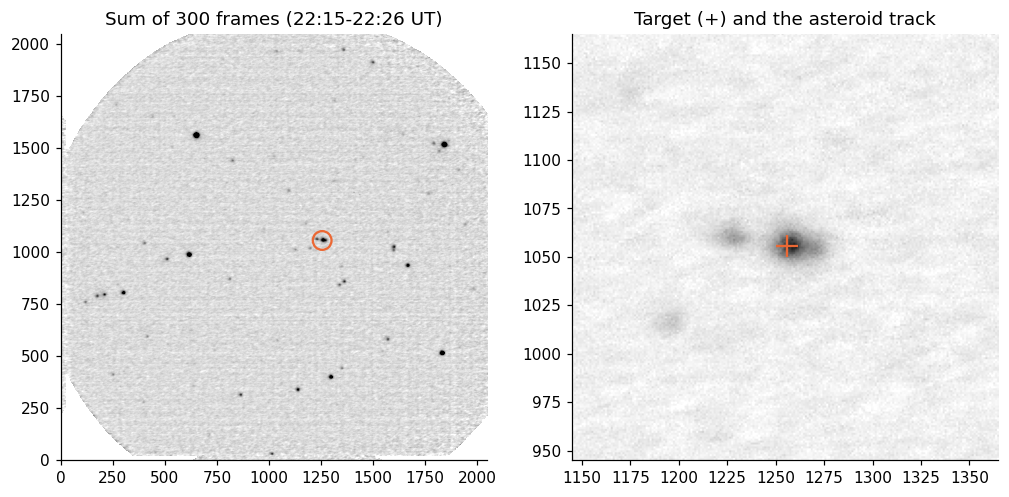

In [10]:
deep = deep_image
in_field = np.hypot(star_x - 1024, star_y - 1024) < 900
catalog_snr = []
for i in np.where(in_field)[0]:
    f, b, n_sky = aperture_photometry(deep, star_x[i], star_y[i], 15, (30, 45))
    catalog_snr.append((gmag[i], f / flux_error(f, deep_frames * sky_1, 15, n_sky, deep_frames)))
catalog_snr = np.array(catalog_snr)
print(' G range    stars  median SNR  detected (SNR >= 5)')
for low in np.arange(12, 20, 1.0):
    m = (catalog_snr[:, 0] >= low) & (catalog_snr[:, 0] < low + 1)
    if m.sum():
        print(f"{low:4.0f}-{low + 1:<4.0f}  {m.sum():6d}  {np.median(catalog_snr[m, 1]):10.1f}  {np.mean(catalog_snr[m, 1] >= 5) * 100:6.0f} %")

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
background = np.nanmedian(deep)
noise = 1.4826 * np.nanmedian(np.abs(deep - background))
ax[0].imshow(deep, origin='lower', cmap='gray_r', vmin=background - 2 * noise, vmax=background + 12 * noise)
ax[0].add_patch(plt.Circle(target_position, 45, fill=False, color=ORANGE, lw=1.5))
ax[0].set_title(f'Sum of {deep_frames} frames (22:15-22:26 UT)')
half = 110
x0, y0 = target_position.astype(int)
ax[1].imshow(deep[y0 - half:y0 + half, x0 - half:x0 + half], origin='lower', cmap='gray_r', extent=(x0 - half, x0 + half, y0 - half, y0 + half),
             vmin=background - 2 * noise, vmax=background + 30 * noise)
ax[1].plot(*target_position, '+', color=ORANGE, ms=14, mew=1.5)
ax[1].set_title('Target (+) and the asteroid track')
for a in ax:
    a.grid(False)
plt.show()

## Differential light curve
$$\Delta m = -2.5 \log_{10} \frac{F_\mathrm{target}}{\sum_i F_{\mathrm{comp},i}}$$
The error combines the CCD equation of the target with that of the summed comparison stars. The model line is not fitted to the time series: it predicts the rise from the asteroid track, the PSF of the brightest comparison star, and the flux of the star and the asteroid measured while they are separated.

In [11]:
stack_table = Table(rows=[(p['seq'], p['n_frames'], p['exptime'], p['mjd'], p['kind']) for p in stack_list],
                    names=['seq', 'n_frames', 'exptime', 'mjd', 'kind'])
flux = np.array([p['flux'] for p in stack_list])
blank_std = np.array([p['blank_std'] for p in stack_list])
blank_mean = np.array([p['blank_mean'] for p in stack_list])
n_frames = np.array(stack_table['n_frames'])

# Photon noise of the star plus the scatter measured in blank apertures of the same stack
error = np.sqrt(np.clip(flux, 0, None) / GAIN + blank_std[:, np.newaxis] ** 2)
comparison = flux[:, 1:].sum(axis=1)
comparison_error = np.sqrt((error[:, 1:] ** 2).sum(axis=1))
ratio = flux[:, 0] / comparison
print(f"Blank apertures: mean offset {np.median(blank_mean / blank_std):+.2f} sigma, scatter per frame added in quadrature "
      f"{np.median(blank_std[stack_table['kind'] == 'event bin'] / np.sqrt(N_EVENT)):.0f} ADU (read noise and sky predict {flux_error(0, sky_1, APERTURE, 1e6):.0f} ADU)")
stack_table['flux_target'] = flux[:, 0]
stack_table['flux_comparison'] = comparison
stack_table['snr_target'] = flux[:, 0] / error[:, 0]
stack_table['delta_mag'] = -2.5 * np.log10(ratio)
stack_table['delta_mag_err'] = 1.0857 * np.sqrt((error[:, 0] / flux[:, 0]) ** 2 + (comparison_error / comparison) ** 2)
stack_table['utc'] = [to_datetime(t).strftime('%Y-%m-%dT%H:%M:%S.%f')[:-3] for t in stack_table['mjd']]
stack_table.write('lightcurve.csv', format='ascii.csv', overwrite=True)

for row in stack_table[stack_table['kind'] != 'event bin']:
    print(f"{row['seq']:>8s}  N = {row['n_frames']:3d}  {row['exptime']:7.2f} s  {row['utc'][11:19]}  SNR {row['snr_target']:6.1f}  dm = {row['delta_mag']:6.3f} +/- {row['delta_mag_err']:.3f}")
event = stack_table['kind'] == 'event bin'
for name in EVENT_CUBES:
    m = event & (stack_table['seq'] == name)
    print(f"{name}: bins of {N_EVENT} frames, median SNR from photon noise and blank apertures {np.median(stack_table['snr_target'][m]):.1f}, "
          f"scatter of the bins {1.4826 * np.median(np.abs(stack_table['delta_mag'][m] - np.median(stack_table['delta_mag'][m]))):.3f} mag, "
          f"median error {np.median(stack_table['delta_mag_err'][m]):.3f} mag")

Blank apertures: mean offset +0.39 sigma, scatter per frame added in quadrature 255 ADU (read noise and sky predict 185 ADU)
  202451  N =   1    30.00 s  20:25:06  SNR  160.0  dm =  2.967 +/- 0.007
  202833  N =   1    30.00 s  20:28:47  SNR  174.7  dm =  2.977 +/- 0.006
  203217  N =   1    30.00 s  20:32:31  SNR  165.7  dm =  2.966 +/- 0.007
  203532  N =   1    30.00 s  20:35:47  SNR  163.0  dm =  2.973 +/- 0.007
  205830  N =  10     3.00 s  21:00:45  SNR    5.5  dm =  3.315 +/- 0.200
  210956  N =  10     3.00 s  21:12:11  SNR    6.4  dm =  3.375 +/- 0.170
  211959  N =  10     3.00 s  21:20:03  SNR    8.4  dm =  3.133 +/- 0.131
  214211  N =  10     3.00 s  21:42:26  SNR   11.5  dm =  3.042 +/- 0.095
  220025  N =  10     5.00 s  22:00:29  SNR   18.2  dm =  3.118 +/- 0.060
  220333  N =  10     4.00 s  22:03:37  SNR   18.2  dm =  2.902 +/- 0.060
  220826  N =  10     3.00 s  22:08:30  SNR   12.3  dm =  2.978 +/- 0.089
  221526  N = 100    30.00 s  22:16:16  SNR   40.1  dm =  2.3

In [12]:
# Prediction of the blend. psf_fraction(d): flux of a star in an aperture displaced by d, from C1 on the deep image
comparison_1 = comparison_positions[0]
reference_flux = aperture_photometry(deep, *comparison_1, APERTURE)[0]
distances = np.arange(0, 91, 3.0)
fractions = np.array([aperture_photometry(deep, comparison_1[0] + d, comparison_1[1], APERTURE)[0] / reference_flux
                      for d in distances])
fractions = np.clip(fractions, 0, 1)
fractions[distances >= 66] = 0

ut = ut_hours(stack_table['mjd'])
star_30s = stack_table['kind'] == 'single'
star_short = (stack_table['kind'] == 'short cube') & (ut < PRE_BLEND_END)
ratio_star = np.average(ratio[star_30s], weights=1 / stack_table['delta_mag_err'][star_30s] ** 2)
mag_short = np.average(stack_table['delta_mag'][star_short], weights=1 / stack_table['delta_mag_err'][star_short] ** 2)
print(f"Star alone: dm = {-2.5 * np.log10(ratio_star):.3f} in the 30 s frames, {mag_short:.3f} in the short stacks "
      f"(scatter of these {np.std(stack_table['delta_mag'][star_short]):.3f} mag)")

# Flux of the asteroid while it is separated from the star, in the same aperture and relative to the same comparison stars
asteroid_ratios = []
for s in sequences:
    if s['name'] in ('220025', '220333', '220826', '214211', '211959'):
        frames = read_corrected(s)
        times = frame_times(s)
        image = stack_frames(frames, shifts[s['name']])
        x, y = track_position(times.mean())
        f = aperture_photometry(image, x, y, APERTURE)[0]
        c = np.sum([aperture_photometry(image, *p, APERTURE)[0] for p in comparison_positions])
        asteroid_ratios.append(f / c)
ratio_asteroid = np.median(asteroid_ratios)
print(f"Star flux / comparison:     {ratio_star:.3f}")
print(f"Asteroid flux / comparison: {ratio_asteroid:.3f}  (asteroid - star = {-2.5 * np.log10(ratio_asteroid / ratio_star):+.2f} mag, published V - G = 14.21 - 14.65 = -0.44 mag)")


def model_ratio(mjd, star_present=True):
    x, y = track_position(mjd)
    d = np.hypot(x - target_position[0], y - target_position[1])
    return (ratio_star if star_present else 0) + ratio_asteroid * np.interp(d, distances, fractions)


plateau_mask = np.isin(stack_table['seq'], ['222213', '222434']) & (stack_table['kind'] == 'whole cube')
ratio_plateau = ratio[plateau_mask].mean()
depth_expected = ratio_star / ratio_plateau
drop_expected = -2.5 * np.log10(1 - depth_expected)
print(f"Measured blend / comparison: {ratio_plateau:.3f},  model {model_ratio(stack_table['mjd'][plateau_mask]).mean():.3f}")
print(f"Expected occultation: flux down by {depth_expected * 100:.0f} %, or {drop_expected:.2f} mag (published 0.6 mag)")
print(f"With the star level of the short stacks instead: {(10 ** (-0.4 * mag_short)) / ratio_plateau * 100:.0f} %")

Star alone: dm = 2.971 in the 30 s frames, 3.045 in the short stacks (scatter of these 0.151 mag)


Star flux / comparison:     0.065
Asteroid flux / comparison: 0.107  (asteroid - star = -0.54 mag, published V - G = 14.21 - 14.65 = -0.44 mag)
Measured blend / comparison: 0.177,  model 0.170
Expected occultation: flux down by 37 %, or 0.49 mag (published 0.6 mag)
With the star level of the short stacks instead: 34 %


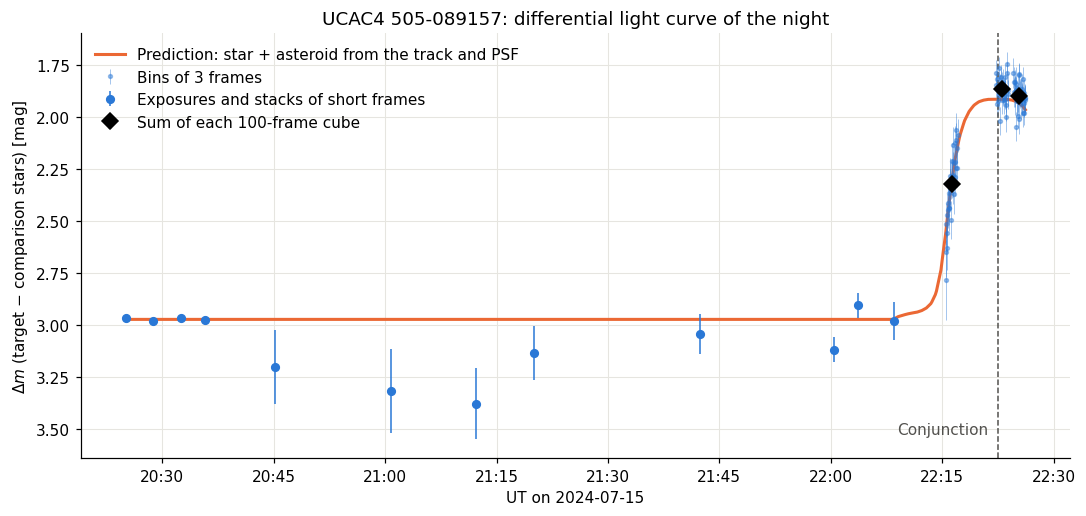

In [13]:
level = -2.5 * np.log10(ratio_star)
model_times = np.linspace(stack_table['mjd'].min(), stack_table['mjd'].max(), 800)
model_times = model_times[ut_hours(model_times) > 20.4]

fig, ax = plt.subplots(figsize=(10, 4.8))
m = ~event & (stack_table['kind'] != 'whole cube')
times = np.array(to_datetime(np.array(stack_table['mjd'])))
ax.plot(to_datetime(model_times), -2.5 * np.log10(model_ratio(model_times)), color=ORANGE, lw=2,
        label='Prediction: star + asteroid from the track and PSF')
ax.errorbar(times[event], stack_table['delta_mag'][event], yerr=stack_table['delta_mag_err'][event], fmt='o', ms=2.5, color=BLUE, alpha=0.45, elinewidth=0.6,
            label=f'Bins of {N_EVENT} frames')
ax.errorbar(times[m], stack_table['delta_mag'][m], yerr=stack_table['delta_mag_err'][m], fmt='o', ms=5, color=BLUE, elinewidth=1,
            label='Exposures and stacks of short frames')
whole = stack_table['kind'] == 'whole cube'
ax.errorbar(times[whole], stack_table['delta_mag'][whole], yerr=stack_table['delta_mag_err'][whole], fmt='D', ms=7, color='black',
            label='Sum of each 100-frame cube')
ax.axvline(to_datetime(mjd_conjunction), color=GREY, lw=1, ls='--')
ax.annotate('Conjunction', (to_datetime(mjd_conjunction), level + 0.55), xytext=(-6, 0), textcoords='offset points', ha='right', color=GREY)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.set_xlabel('UT on 2024-07-15')
ax.set_ylabel(r'$\Delta m$ (target $-$ comparison stars) [mag]')
ax.set_title('UCAC4 505-089157: differential light curve of the night')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
fig.savefig('lightcurve_night.png', dpi=200)
plt.show()

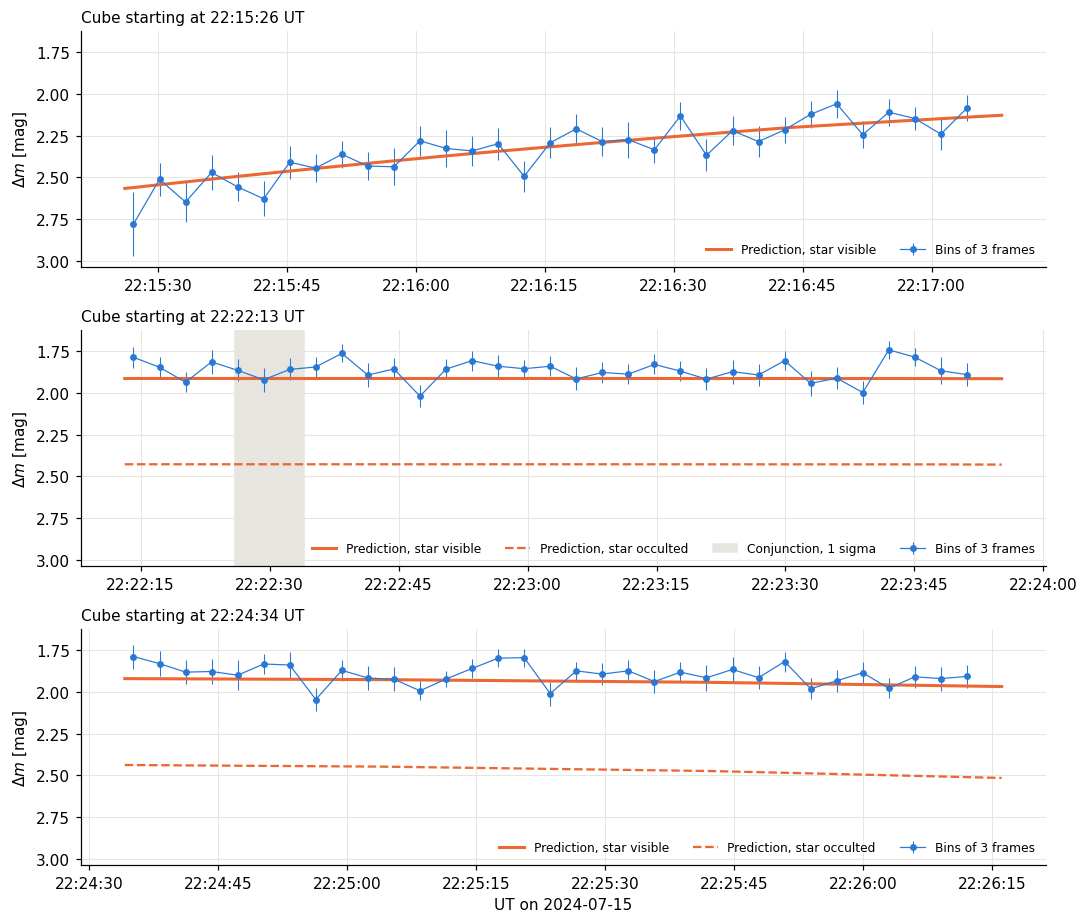

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharey=True)
for name, ax in zip(EVENT_CUBES, axes):
    m = event & (stack_table['seq'] == name)
    start = frame_times(next(s for s in sequences if s['name'] == name))[0]
    ax.errorbar(times[m], stack_table['delta_mag'][m], yerr=stack_table['delta_mag_err'][m], fmt='o-', ms=3.5, lw=0.8, color=BLUE, elinewidth=0.7,
                label=f'Bins of {N_EVENT} frames')
    span = np.linspace(start, start + 102 / 86400, 100)
    ax.plot(to_datetime(span), -2.5 * np.log10(model_ratio(span)), color=ORANGE, lw=2, label='Prediction, star visible')
    if name != '221526':
        ax.plot(to_datetime(span), -2.5 * np.log10(model_ratio(span, star_present=False)), color=ORANGE, lw=1.5, ls='--', label='Prediction, star occulted')
    if span[0] < mjd_conjunction < span[-1]:
        ax.axvspan(to_datetime(mjd_conjunction - sigma_conjunction / 86400), to_datetime(mjd_conjunction + sigma_conjunction / 86400), color='#e6e5e0', zorder=0, label='Conjunction, 1 sigma')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
    ax.set_ylabel(r'$\Delta m$ [mag]')
    ax.set_title(f'Cube starting at {to_datetime(start).strftime("%H:%M:%S")} UT', loc='left', fontsize=10)
    ax.legend(frameon=False, ncols=4, fontsize=8, loc='lower right')
axes[0].invert_yaxis()
axes[-1].set_xlabel('UT on 2024-07-15')
fig.tight_layout()
fig.savefig('lightcurve_event_cubes.png', dpi=200)
plt.show()

## Search for the occultation
The cubes are searched at the full 1 s resolution with sliding boxes, against the depth expected from the measured flux of star and asteroid. To see what the data could have detected, an occultation of the expected depth is also injected at every position of the real light curve of the cube.

Expected depth: 37 % of the blend flux for about 7 s

cube     width[s]  deepest box  at UT        significance  (expected significance of the occultation)
221526       3        0.774  22:15:36           2.5           4.1
221526       5        0.919  22:15:36           1.2           5.3
221526       7        0.894  22:15:37           1.8           6.3
222213       3        0.862  22:22:46           2.5           6.7
222213       5        0.880  22:23:35           2.9           8.7
222213       7        0.923  22:23:34           2.2          10.3
222434       3        0.862  22:24:55           2.3           6.2
222434       5        0.882  22:25:06           2.6           8.0
222434       7        0.922  22:25:06           2.0           9.4
Injected occultations of 7 s recovered at >= 5 sigma in 222213: 100 %
Injected occultations of 7 s recovered at >= 5 sigma in 222434: 100 %

The scatter per frame is 0.094. Upper limit on a 7 s dip in 222213 (5 sigma): 18 % of the blend flux

Time co

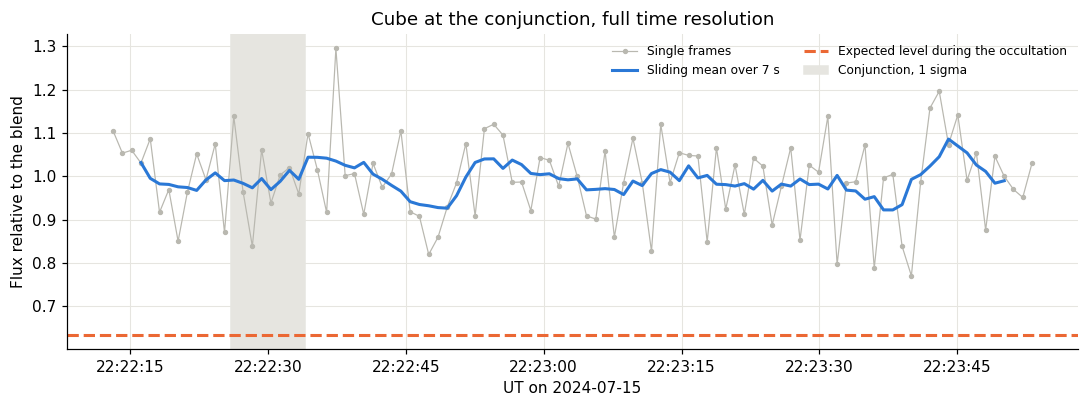

In [15]:
def normalised_series(name):
    """Target / comparison per frame, divided by the prediction of the blend and normalised."""
    m = frame_table['seq'] == name
    series = frame_table['flux'][m, 0] / frame_table['flux'][m, 1:].sum(axis=1)
    series = series / model_ratio(frame_table['mjd'][m])
    return series / np.median(series), frame_table['mjd'][m]


def box_search(series, width):
    box = np.convolve(series, np.ones(width) / width, mode='valid')
    noise = np.std(series) / np.sqrt(width)
    return box, (1 - box) / noise


print(f"Expected depth: {depth_expected * 100:.0f} % of the blend flux for about {EVENT_DURATION:.0f} s\n")
print('cube     width[s]  deepest box  at UT        significance  (expected significance of the occultation)')
for name in EVENT_CUBES:
    series, mjd = normalised_series(name)
    sigma = np.std(series)
    for width in (3, 5, 7):
        box, significance = box_search(series, width)
        best = significance.argmax()
        expected = depth_expected / (sigma / np.sqrt(width))
        print(f"{name}  {width:6d}  {box[best]:11.3f}  {to_datetime(mjd[best]).strftime('%H:%M:%S')}  {significance[best]:12.1f}  {expected:12.1f}")

# Injection test
for name in ['222213', '222434']:
    series, mjd = normalised_series(name)
    found = []
    for start in range(len(series) - 7 + 1):
        test = series.copy()
        test[start:start + 7] *= 1 - depth_expected
        _, significance = box_search(test, 7)
        found.append(significance[max(start - 3, 0):start + 4].max() >= 5)
    print(f"Injected occultations of 7 s recovered at >= 5 sigma in {name}: {np.mean(found) * 100:.0f} %")
series, mjd = normalised_series('222213')
sigma = np.std(series)
print(f"\nThe scatter per frame is {sigma:.3f}. Upper limit on a 7 s dip in 222213 (5 sigma): {5 * sigma / np.sqrt(7) * 100:.0f} % of the blend flux")

covered = np.array([(s['mjd_start'], s['mjd_start'] + s['n_frames'] * s['cycle_time'] / 86400) for s in sequences if s['name'] in EVENT_CUBES])
print("\nTime coverage of the event cubes [UT]:")
for start, end in covered:
    print(f"  {to_datetime(start).strftime('%H:%M:%S')} - {to_datetime(end).strftime('%H:%M:%S')}")
print(f"Conjunction {to_datetime(mjd_conjunction).strftime('%H:%M:%S')} +/- {sigma_conjunction:.0f} s (track), "
      f"{to_datetime(mjd_blend).strftime('%H:%M:%S')} +/- {sigma_blend:.0f} s (blend)")

fig, ax = plt.subplots(figsize=(10, 3.8))
series, mjd = normalised_series('222213')
ax.plot(to_datetime(mjd), series, color='#b9b8b0', lw=0.8, marker='o', ms=2.5, label='Single frames')
box, _ = box_search(series, 7)
ax.plot(to_datetime(mjd[3:-3]), box, color=BLUE, lw=2, label='Sliding mean over 7 s')
ax.axhline(1 - depth_expected, color=ORANGE, lw=2, ls='--', label='Expected level during the occultation')
ax.axvspan(to_datetime(mjd_conjunction - sigma_conjunction / 86400), to_datetime(mjd_conjunction + sigma_conjunction / 86400), color='#e6e5e0', zorder=0, label='Conjunction, 1 sigma')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
ax.set_xlabel('UT on 2024-07-15')
ax.set_ylabel('Flux relative to the blend')
ax.set_title('Cube at the conjunction, full time resolution')
ax.legend(frameon=False, ncols=2, fontsize=8)
fig.tight_layout()
fig.savefig('occultation_search.png', dpi=200)
plt.show()

## Stability of the comparison stars
Each comparison star against the sum of the others, per sequence. A variable star would drift here.

C1 G = 12.65: scatter over the night 0.040 mag, median formal error 0.009 mag
C2 G = 13.48: scatter over the night 0.052 mag, median formal error 0.020 mag
C3 G = 14.19: scatter over the night 0.041 mag, median formal error 0.035 mag
C4 G = 14.21: scatter over the night 0.076 mag, median formal error 0.039 mag
C5 G = 14.29: scatter over the night 0.058 mag, median formal error 0.043 mag


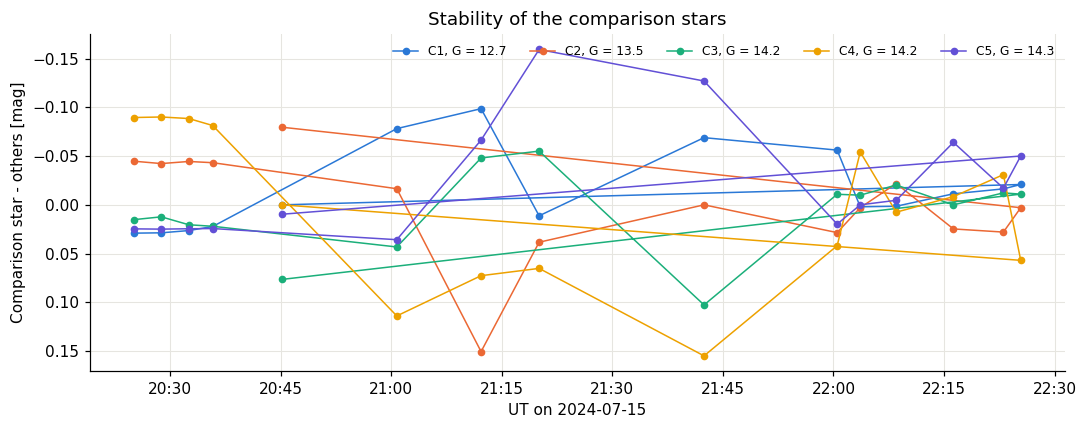

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
palette = [BLUE, ORANGE, '#1baf7a', '#eda100', '#6250d6']
night = stack_table['kind'] != 'event bin'
for c in range(5):
    others = np.delete(flux[:, 1:], c, axis=1).sum(axis=1)
    dm = -2.5 * np.log10(flux[:, c + 1] / others)
    dm = dm - np.nanmedian(dm[night])
    ax.plot(times[night], dm[night], 'o-', ms=4, lw=1, color=palette[c], label=f'C{c + 1}, G = {gmag[comparison_index[c]]:.1f}')
    print(f"C{c + 1} G = {gmag[comparison_index[c]]:.2f}: scatter over the night {np.nanstd(dm[night]):.3f} mag, median formal error {np.median(1.0857 * error[night, c + 1] / flux[night, c + 1]):.3f} mag")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.invert_yaxis()
ax.set_xlabel('UT on 2024-07-15')
ax.set_ylabel('Comparison star - others [mag]')
ax.set_title('Stability of the comparison stars')
ax.legend(frameon=False, ncols=5, fontsize=8)
fig.tight_layout()
plt.show()